# Interpretability of the selected model

We interpret the XGB pipelines selected by cross-validation (`results/los_learning_curve/models/xgb/xgb_pct_0.025_no_interactions_rs*.joblib`), one per random state (42, 84, 126), on each state's held-out test set.

**Global feature importance – three methods**

| Method | What it measures | Units |
|---|---|---|
| XGB built-in importance (`total_gain`) | Total reduction in training loss from all splits on a feature | share of total gain (sums to 1) |
| Permutation importance | How much test RMSE gets worse when one feature's values are shuffled, which breaks its link to LOS | days of RMSE |
| Mean \|SHAP\| | Average absolute contribution of a feature to individual predictions, relative to the reference prediction | days of predicted LOS |

**Local explanation:** SHAP waterfall plots for individual test patients.

The pipeline one-hot encodes the categorical features (e.g. about 200 facility columns). Built-in importances and SHAP values are computed per one-hot column, so we **sum them back to the 11 original features**. This is valid because both quantities are additive. Permutation importance shuffles raw columns, so it is already per original feature.

Figures saved to `figures/`: `xgb_global_importance_3methods.png`, `xgb_shap_by_category.png`, `xgb_shap_waterfall_highest_pred.png`, `xgb_shap_waterfall_long_stay.png`.

In [1]:
import os
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import shap

from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error
import xgboost

c:\Users\nguye\anaconda3\envs\hospital-stay-forecast\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Loading the saved XGB models

In [2]:
_original_setstate = xgboost.core.Booster.__setstate__


def _setstate_portable(self, state):
    try:
        _original_setstate(self, state)
    except xgboost.core.XGBoostError:
        buf = bytes(state["handle"])                        # UBJSON: {"Config": {...}, "Model": {...}}
        key = b"L" + (5).to_bytes(8, "big") + b"Model"      # the length-prefixed key "Model"
        start = buf.find(key)
        assert start != -1, "no Model section in the pickled booster"
        tmp = xgboost.Booster()
        tmp.load_model(bytearray(buf[start + len(key):-1]))  # the Model object only (drop the outer "}")
        self.__dict__.update({k: v for k, v in state.items() if k != "handle"})
        self.handle, tmp.handle = tmp.handle, None           # take ownership of the loaded booster


xgboost.core.Booster.__setstate__ = _setstate_portable

In [3]:
DATA_PATH = "../data/processed/sparcs_2024_final.parquet"
OUTPUT_DIR = "../results/los_learning_curve"
SPLIT_DIR = os.path.join(OUTPUT_DIR, "shared")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models", "xgb")
FIG_DIR = "../figures"

TARGET = "los"
PCT = 0.025
RANDOM_STATES = [42, 84, 126]
LOCAL_RS = 42            # random state used for the individual (local) explanations
N_REPEATS = 10           # permutation repeats

df = pd.read_parquet(DATA_PATH).reset_index(drop=True)
y = df[TARGET]


def model_stem(rs):
    return os.path.join(MODEL_DIR, f"xgb_pct_{PCT:g}_no_interactions_rs{rs}")


# the feature list the model was trained with comes from the saved metadata
with open(model_stem(LOCAL_RS) + "_metadata.json") as f:
    meta = json.load(f)
FEATURES = meta["features"]
print("Features:", FEATURES)
print("Best params (rs42):", meta["best_params"])

Features: ['permanent_facility_id', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity', 'type_of_admission', 'payment_typology_1', 'emergency_department_indicator', 'payment_typology_2', 'payment_typology_3']
Best params (rs42): {'model__colsample_bytree': '0.5', 'model__early_stopping_rounds': '50', 'model__learning_rate': '0.1', 'model__max_depth': '3', 'model__n_estimators': '10000', 'model__n_jobs': '-1', 'n_trees': '390'}


## Helpers

**One-hot column → original feature.** The `ColumnTransformer` outputs the `ordinal` block (age_group, 1 column) followed by the `onehot` block (one column per category of each feature, in order). Repeating each feature name `len(categories)` times gives a map from every model column back to its original feature.

**Sparse zeros are "missing" for XGBoost.** The preprocessor outputs a *sparse* matrix, and XGBoost treats entries that are not stored as **missing**, not as 0. To explain exactly the model that was trained, we densify with NaN in the empty cells instead of 0. The assert checks that XGB predicts identically on this dense matrix and through the original pipeline.

In [4]:
def feature_groups(pipeline):
    # Original feature name for every column the XGB model sees
    pre = pipeline.named_steps["preprocessor"]
    groups = []
    for name, transformer, cols in pre.transformers_:
        if name == "ordinal":
            groups += list(cols)
        elif name == "onehot":
            for col, cats in zip(cols, transformer.categories_):
                groups += [col] * len(cats)
    groups = np.array(groups)
    assert len(groups) == len(pre.get_feature_names_out()), "feature map does not match model columns"
    return groups


def to_dense_with_nan(X_transformed):
    # Dense copy of the model input where non-stored sparse entries are NaN (= missing for XGBoost)
    if not sp.issparse(X_transformed):
        return np.asarray(X_transformed, dtype=float)
    coo = X_transformed.tocoo()
    dense = np.full(coo.shape, np.nan)
    dense[coo.row, coo.col] = coo.data
    return dense


def group_columns(values, groups, features):
    # Sum per-column values (1-D or 2-D) into the original features
    values = np.atleast_2d(values)
    out = np.column_stack([values[:, groups == f].sum(axis=1) for f in features])
    return out

## Compute all three importances for each random state

In [5]:
builtin_rows, perm_rows, shap_rows = [], [], []
local = {}   # everything needed for the local explanations at LOCAL_RS

for rs in RANDOM_STATES:
    pipe = joblib.load(model_stem(rs) + ".joblib")
    xgb_model = pipe.named_steps["model"]
    pre = pipe.named_steps["preprocessor"]

    split = joblib.load(os.path.join(SPLIT_DIR, f"test_split_rs{rs}.joblib"))
    X_test = df[FEATURES].iloc[split["test_idx"]]
    y_test = y.iloc[split["test_idx"]]

    groups = feature_groups(pipe)
    X_dense = to_dense_with_nan(pre.transform(X_test))

    pipe_pred = pipe.predict(X_test)
    saved_pred = pd.read_csv(os.path.join(
        OUTPUT_DIR, "predictions", f"xgb_pct_{PCT:g}_no_interactions_rs{rs}_predictions.csv"))
    assert (saved_pred["row_index"].to_numpy() == split["test_idx"]).all()
    assert np.allclose(pipe_pred, saved_pred["y_pred"], atol=1e-4), "reloaded model differs from the trained model"
    assert np.allclose(xgb_model.predict(X_dense), pipe_pred, atol=1e-4), "dense input changes predictions"
    print(f"rs {rs:>3}: {X_dense.shape[1]} model columns | test RMSE {root_mean_squared_error(y_test, pipe_pred):.4f}")

    # 1) built-in importance: total gain, summed over one-hot columns
    booster = xgb_model.get_booster()
    gain = np.zeros(len(groups))
    names = booster.feature_names
    for key, value in booster.get_score(importance_type="total_gain").items():
        idx = int(key[1:]) if names is None else names.index(key)
        gain[idx] = value
    builtin = group_columns(gain, groups, FEATURES)[0]
    builtin_rows.append(pd.Series(builtin / builtin.sum(), index=FEATURES, name=rs))

    # 2) permutation importance on the raw columns (whole pipeline), scored by RMSE
    perm = permutation_importance(pipe, X_test, y_test, scoring="neg_root_mean_squared_error",
                                  n_repeats=N_REPEATS, random_state=rs, n_jobs=1)
    perm_rows.append(pd.Series(perm.importances_mean, index=FEATURES, name=rs))  # = increase in RMSE (days)

    # 3) SHAP, summed over one-hot columns
    explainer = shap.TreeExplainer(xgb_model)
    shap_cols = explainer.shap_values(X_dense)
    base_value = float(np.ravel(explainer.expected_value)[0])
    shap_grouped = group_columns(shap_cols, groups, FEATURES)
    assert np.allclose(base_value + shap_grouped.sum(axis=1), pipe_pred, atol=1e-3), "SHAP additivity failed"
    shap_rows.append(pd.Series(np.abs(shap_grouped).mean(axis=0), index=FEATURES, name=rs))

    if rs == LOCAL_RS:
        local = {"X_test": X_test, "y_test": y_test, "pred": pipe_pred,
                 "shap": pd.DataFrame(shap_grouped, columns=FEATURES, index=X_test.index),
                 "base": base_value}

print("All feature-map, dense-prediction and SHAP-additivity checks passed.")

rs  42: 304 model columns | test RMSE 8.5206
rs  84: 303 model columns | test RMSE 8.8104
rs 126: 302 model columns | test RMSE 8.4527
All feature-map, dense-prediction and SHAP-additivity checks passed.


In [6]:
def summarise(rows):
    table = pd.concat(rows, axis=1)
    return pd.DataFrame({"mean": table.mean(axis=1), "std": table.std(axis=1, ddof=0)})


importance = {
    "XGB built-in (total gain share)": summarise(builtin_rows),
    "Permutation (RMSE increase, days)": summarise(perm_rows),
    "Mean |SHAP| (days)": summarise(shap_rows),
}

# one overview table, features ordered by mean |SHAP|
feature_order = importance["Mean |SHAP| (days)"]["mean"].sort_values(ascending=False).index
overview = pd.concat({k: v["mean"] for k, v in importance.items()}, axis=1).loc[feature_order]
overview.round(4)

,XGB built-in (total gain share),"Permutation (RMSE increase, days)",Mean |SHAP| (days)
permanent_facility_id,0.4493,0.4876,0.8197
age_group,0.0805,0.0555,0.4886
gender,0.0529,0.0363,0.4126
type_of_admission,0.0826,0.0811,0.3962
payment_typology_1,0.0777,0.0373,0.3535
payment_typology_2,0.0542,0.0284,0.2772
race,0.0410,0.0079,0.1589
zip_code,0.0956,0.0334,0.1263
ethnicity,0.0225,0.0074,0.1163
payment_typology_3,0.0185,0.0100,0.0649


## Figure: the three global importance methods side by side

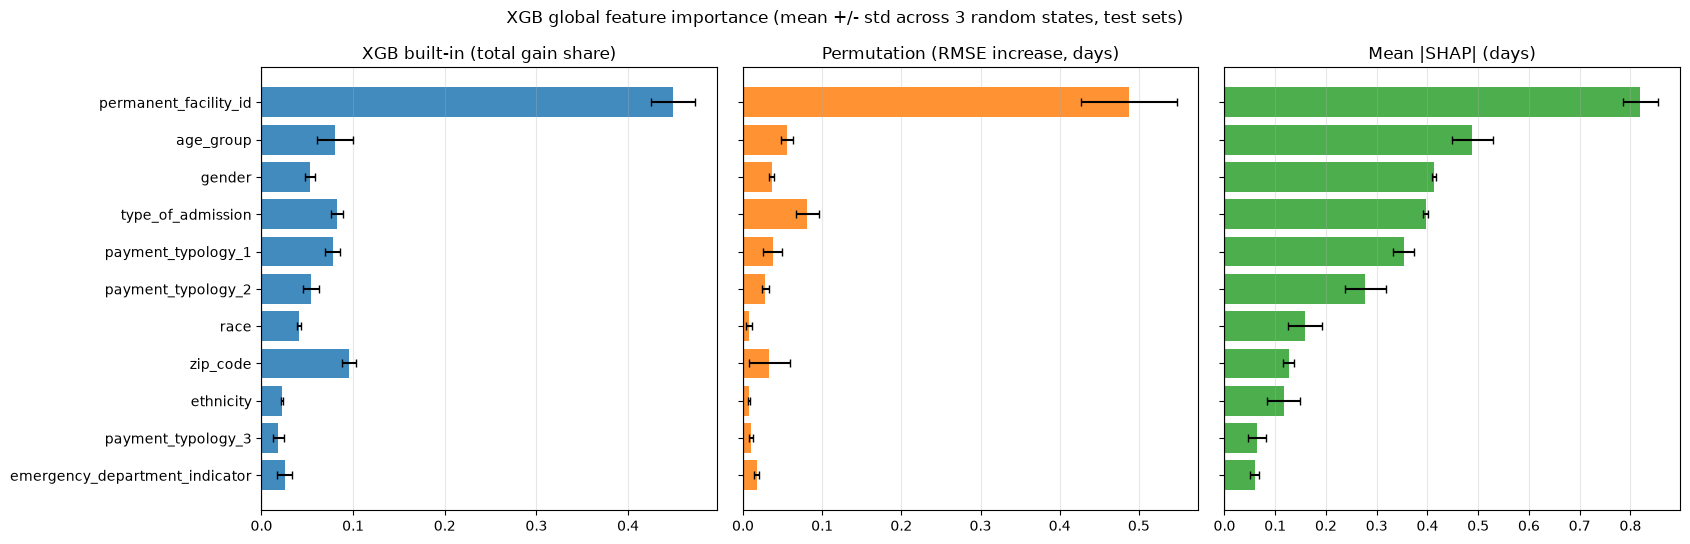

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
colors = ["tab:blue", "tab:orange", "tab:green"]
plot_order = feature_order[::-1]   # largest at the top

for ax, (title, table), color in zip(axes, importance.items(), colors):
    t = table.loc[plot_order]
    ax.barh(t.index, t["mean"], xerr=t["std"], color=color, alpha=0.85, capsize=3)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="x")
    ax.axvline(0, color="k", lw=0.8)

fig.suptitle(f"XGB global feature importance (mean +/- std across {len(RANDOM_STATES)} random states, test sets)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "xgb_global_importance_3methods.png"), dpi=300, bbox_inches="tight")
plt.show()

## Figure: which categories push predictions up or down?

The global importances say *how much* a feature matters, not *in which direction*. For the four most important features (by mean |SHAP|), the plot shows the average SHAP value for each category (the most frequent categories only) on the `LOCAL_RS` test set. Positive values push the predicted LOS **above** the reference prediction; negative values push it below.

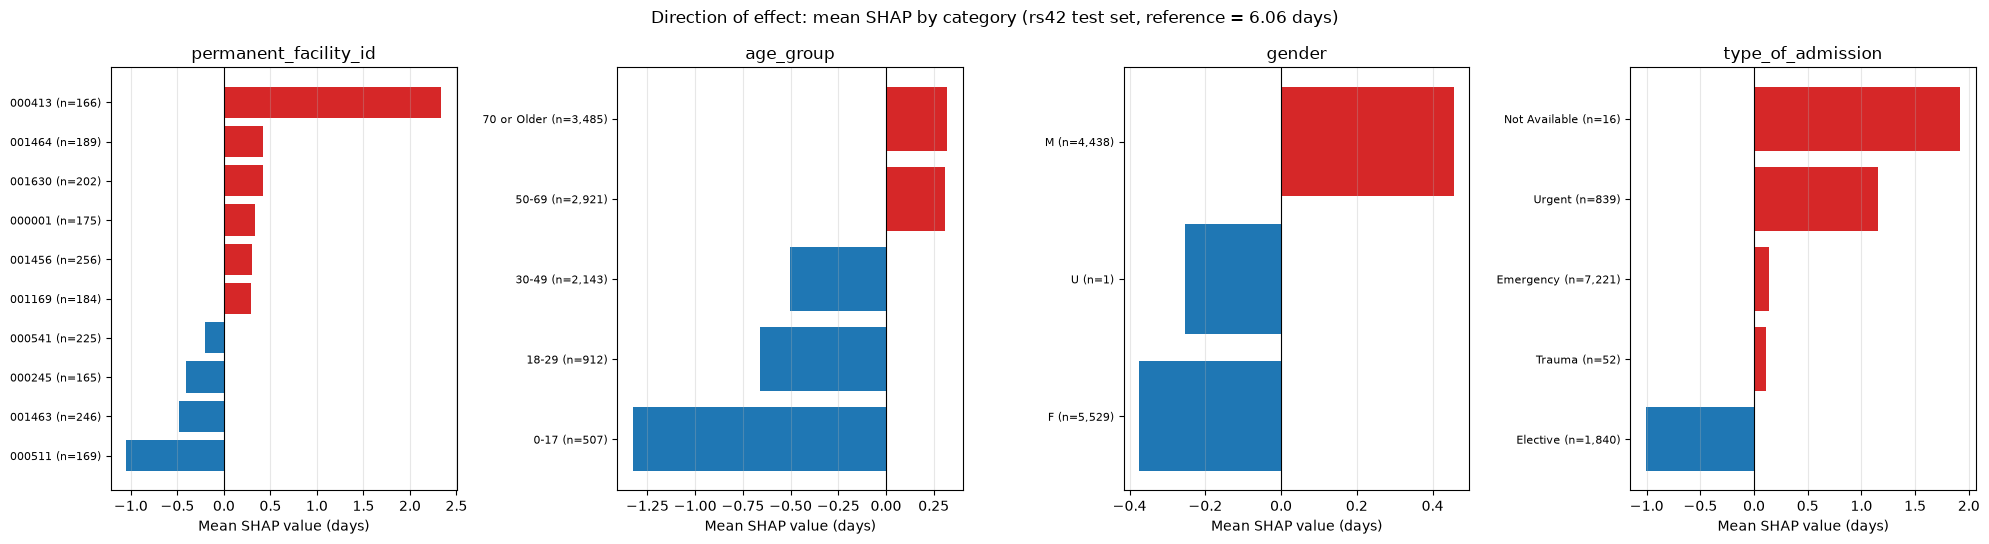

In [8]:
TOP_K_FEATURES = 4
TOP_N_CATS = 10

top_features = list(feature_order[:TOP_K_FEATURES])
fig, axes = plt.subplots(1, TOP_K_FEATURES, figsize=(5 * TOP_K_FEATURES, 5.5))

for ax, feat in zip(axes, top_features):
    tmp = pd.DataFrame({"category": local["X_test"][feat].astype(str), "shap": local["shap"][feat]})
    stats = tmp.groupby("category")["shap"].agg(["mean", "size"])
    stats = stats.sort_values("size", ascending=False).head(TOP_N_CATS).sort_values("mean")
    bar_colors = np.where(stats["mean"] >= 0, "tab:red", "tab:blue")
    ax.barh([f"{c} (n={n:,})" for c, n in zip(stats.index, stats["size"])], stats["mean"], color=bar_colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(feat)
    ax.set_xlabel("Mean SHAP value (days)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(alpha=0.3, axis="x")

fig.suptitle(f"Direction of effect: mean SHAP by category (rs{LOCAL_RS} test set, reference = {local['base']:.2f} days)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "xgb_shap_by_category.png"), dpi=300, bbox_inches="tight")
plt.show()

## Local explanations: SHAP waterfall plots

The SHAP values for one patient add up exactly to: prediction = reference prediction (`E[f(x)]`, the model's average prediction over the training data) + sum of that patient's feature contributions.

We explain two patients from the rs42 test set:

- **(a) highest predicted LOS:** what drives the model's longest-stay predictions?
- **(b) a typical long-stay patient** (true LOS ≥ 30 days, the one with the median prediction in that group): why does the model under-predict long stays?


=== Highest predicted LOS (row 1963525) ===
Reference prediction E[f(x)]: 6.06 days
Model prediction f(x):        80.06 days
True LOS:                     62 days


,value,shap (days)
permanent_facility_id,001486,64.056999
ethnicity,Unknown,11.393000
zip_code,112,2.021000
gender,F,-1.413000
age_group,30-49,-1.035000
type_of_admission,Elective,-0.921000
payment_typology_1,Medicaid,0.276000
race,Black/African American,-0.243000
emergency_department_indicator,N,-0.060000
payment_typology_2,No second payer,-0.053000


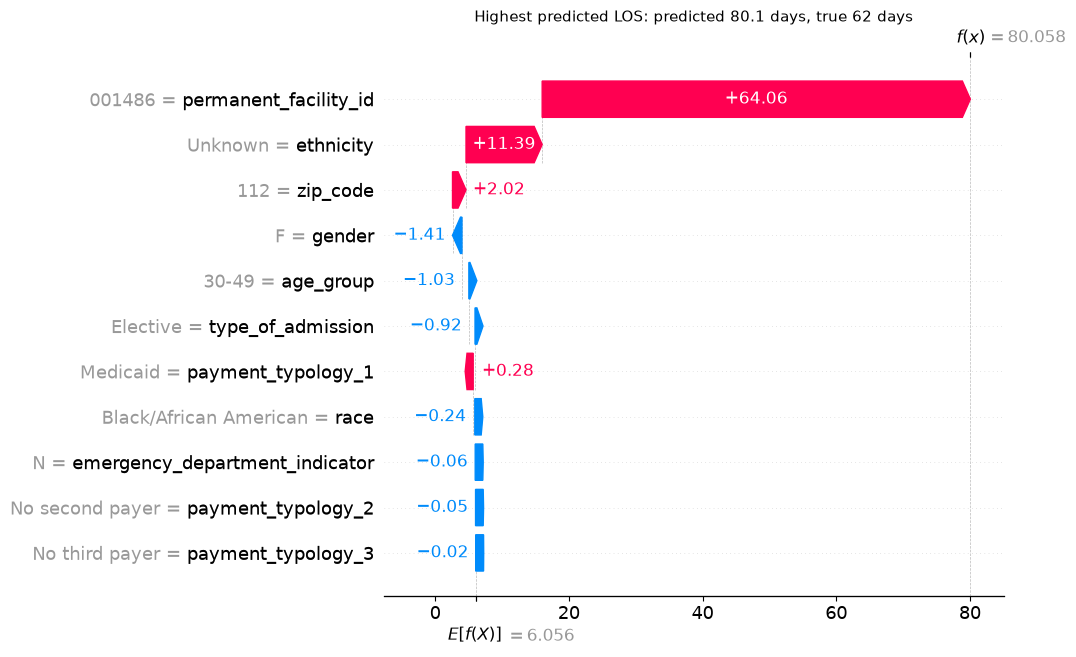


=== Typical long-stay patient (true LOS >= 30) (row 253538) ===
Reference prediction E[f(x)]: 6.06 days
Model prediction f(x):        6.77 days
True LOS:                     71 days


,value,shap (days)
permanent_facility_id,001458,0.681
payment_typology_1,Private Health Insurance,-0.578
gender,M,0.479
age_group,50-69,0.323
payment_typology_2,No second payer,-0.190
type_of_admission,Emergency,0.152
race,White,-0.127
payment_typology_3,No third payer,-0.021
emergency_department_indicator,Y,0.010
ethnicity,Not Span/Hispanic,-0.009


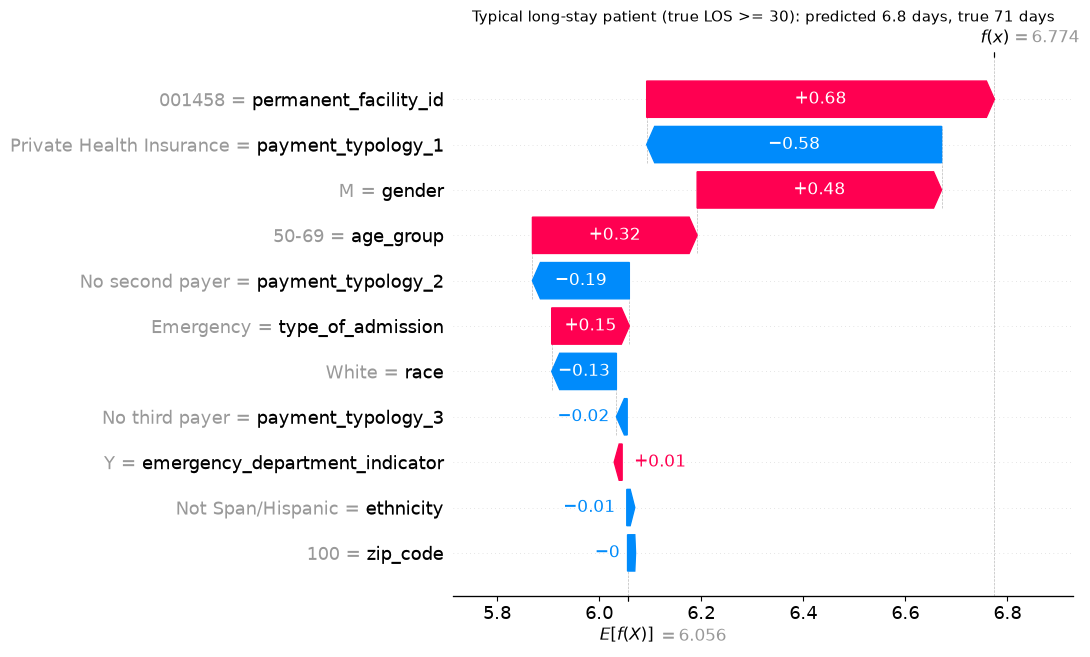

In [10]:
pred = pd.Series(local["pred"], index=local["X_test"].index)
y_loc = local["y_test"]

case_a = pred.idxmax()
long_stays = pred[y_loc >= 30]
case_b = (long_stays - long_stays.median()).abs().idxmin()

CASES = {"highest_pred": case_a, "long_stay": case_b}


def explain_patient(row_id, label, fname):
    values = local["shap"].loc[row_id].to_numpy()
    expl = shap.Explanation(
        values=values,
        base_values=local["base"],
        data=local["X_test"].loc[row_id].astype(str).to_numpy(),
        feature_names=FEATURES,
    )
    print(f"\n=== {label} (row {row_id}) ===")
    print(f"Reference prediction E[f(x)]: {local['base']:.2f} days")
    print(f"Model prediction f(x):        {pred[row_id]:.2f} days")
    print(f"True LOS:                     {y_loc[row_id]} days")
    contrib = pd.DataFrame({"value": expl.data, "shap (days)": values}, index=FEATURES)
    display(contrib.sort_values("shap (days)", key=np.abs, ascending=False).round(3))

    plt.figure()
    shap.plots.waterfall(expl, max_display=12, show=False)
    plt.title(f"{label}: predicted {pred[row_id]:.1f} days, true {y_loc[row_id]} days", fontsize=11)
    plt.savefig(os.path.join(FIG_DIR, fname), dpi=300, bbox_inches="tight")
    plt.show()


explain_patient(case_a, "Highest predicted LOS", "xgb_shap_waterfall_highest_pred.png")
explain_patient(case_b, "Typical long-stay patient (true LOS >= 30)", "xgb_shap_waterfall_long_stay.png")

## Previous Work
- https://thesai.org/Publications/ViewPaper?Code=IJACSA&Issue=3&SerialNo=86&Volume=17
- https://arxiv.org/abs/2409.17786

## Discussion